<a href="https://colab.research.google.com/github/AAMINABIBI/-calculator-using-HTML-CSS-JavaScript/blob/main/DL/MLP_House_Price_Prediction_CaseStudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Layer Perceptron (MLP) with PyTorch
## Case Study: House Price Prediction 🏠

**Problem:** Humein ghar ki kuch details di gayi hain aur MLP se us ghar ki estimated price predict karni hai.

Features:
1. Area (square feet)
2. Bedrooms
3. House age (years)

**Target:** House price (in lakh PKR)

Is notebook mein hum scratch se ek basic lekin complete MLP workflow banayenge: data generation, train/test split, scaling, tensors, model, loss, optimizer, training, evaluation aur new prediction.

**Note:** Data synthetic/demo hai. Real property prices market, location aur condition par depend karti hain. Har cell ko order mein `Shift + Enter` se run karein.

## Step 1: Libraries import karein

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

torch.manual_seed(42)
np.random.seed(42)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


## Step 2: Dataset banayein
Real dataset ki jagah learning ke liye synthetic data banaya gaya hai.

General rule: bara area aur zyada bedrooms price ko barhate hain, jabke purana ghar price ko kuch kam kar sakta hai. Random noise bhi add kiya gaya hai taake data bilkul perfect na ho.

In [2]:
n = 600

area = np.random.uniform(500, 3500, n)          # square feet
bedrooms = np.random.randint(1, 7, n)            # 1 to 6
age = np.random.uniform(0, 40, n)                # years

# Demo formula: price in lakh PKR
noise = np.random.normal(0, 12, n)
price = 20 + 0.035 * area + 8 * bedrooms - 0.7 * age + noise
price = np.maximum(price, 15)                    # price ko positive rakhein

X = np.column_stack([area, bedrooms, age]).astype(np.float32)
y = price.astype(np.float32).reshape(-1, 1)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("First 5 rows (area, bedrooms, age):\n", X[:5])
print("First 5 prices (lakh PKR):\n", y[:5].flatten())

Features shape: (600, 3)
Target shape: (600, 1)
First 5 rows (area, bedrooms, age):
 [[1.6236204e+03 5.0000000e+00 2.3609226e+01]
 [3.3521428e+03 2.0000000e+00 1.4438956e+01]
 [2.6959819e+03 4.0000000e+00 3.6632829e+00]
 [2.2959753e+03 2.0000000e+00 3.6692543e+01]
 [9.6805591e+02 5.0000000e+00 5.4727454e+00]]
First 5 prices (lakh PKR):
 [103.93248 136.80795 124.31851  97.43451  76.84168]


## Step 3: Data ko Train aur Test mein divide karein
- **80% Train:** model is data se seekhega.
- **20% Test:** training ke baad performance check hogi.

Test data ko training ke dauran model ko nahi dikhana chahiye.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 480
Testing samples: 120


## Step 4: Feature Scaling
Area, bedrooms aur age ki ranges mukhtalif hain. `StandardScaler` input features ko comparable scale par lata hai.

Important: scaler ko sirf training data par `fit` karein. Test data par sirf `transform` karein.

In [4]:
x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Target price ko bhi scale karte hain, training ko stable banane ke liye
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train)
y_test_scaled = y_scaler.transform(y_test)

## Step 5: NumPy arrays ko PyTorch Tensors mein convert karein
PyTorch model tensors par kaam karta hai. `DataLoader` training data ko chhote batches mein deta hai.

In [5]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print("One batch shapes:", next(iter(train_loader))[0].shape,
      next(iter(train_loader))[1].shape)

One batch shapes: torch.Size([32, 3]) torch.Size([32, 1])


## Step 6: MLP Model banayein

Architecture:

```text
Input (3 features)
       ↓
Hidden Layer (16 neurons + ReLU)
       ↓
Hidden Layer (8 neurons + ReLU)
       ↓
Output (1 value: predicted scaled price)
```

- `Linear`: weights aur bias ke zariye calculation karta hai.
- `ReLU`: network mein non-linearity lata hai.
- Output layer mein activation nahi lagate, kyun ke yeh regression problem hai aur price ek continuous number hai.

In [6]:
class HousePriceMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)

model = HousePriceMLP()
print(model)

HousePriceMLP(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)


## Step 7: Loss Function aur Optimizer

- **MSELoss:** actual aur predicted price ke darmiyan squared error calculate karta hai.
- **Adam:** model ke weights update karta hai taake loss kam ho.
- **Learning rate (0.01):** har update ka step size.

In [7]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

## Step 8: Model Training (Forward + Backpropagation)

Har batch par:
1. Forward pass: prediction nikalna
2. Loss calculate karna
3. `zero_grad()`: purane gradients clear karna
4. `backward()`: gradients calculate karna
5. `step()`: weights update karna

**Epoch** ka matlab poore training dataset par ek complete pass hai.

In [8]:
epochs = 150
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for xb, yb in train_loader:
        predictions = model(xb)
        loss = criterion(predictions, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    loss_history.append(average_loss)

    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:3d}/{epochs} | Loss: {average_loss:.4f}")

Epoch  15/150 | Loss: 0.1004
Epoch  30/150 | Loss: 0.1037
Epoch  45/150 | Loss: 0.0977
Epoch  60/150 | Loss: 0.0974
Epoch  75/150 | Loss: 0.0993
Epoch  90/150 | Loss: 0.0950
Epoch 105/150 | Loss: 0.0938
Epoch 120/150 | Loss: 0.0986
Epoch 135/150 | Loss: 0.0983
Epoch 150/150 | Loss: 0.0972


## Step 9: Training Loss ka graph

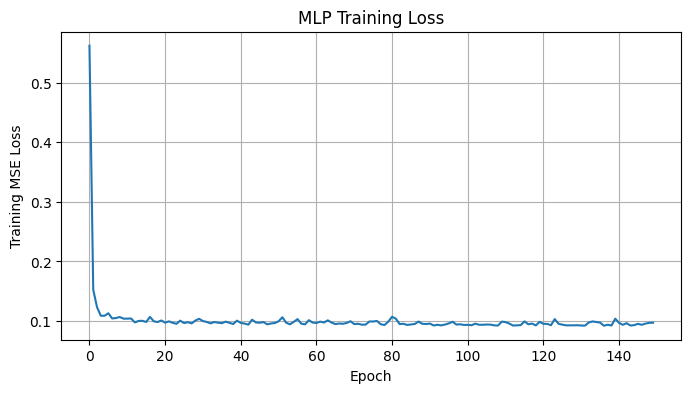

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("MLP Training Loss")
plt.grid(True)
plt.show()

## Step 10: Test Data par Evaluation

Ab model ko unseen test data par check karte hain. Predictions ko original lakh PKR scale par wapas convert karenge.

Metrics:
- **MAE:** average absolute error; jitna kam ho utna behtar.
- **RMSE:** large errors ko zyada penalty deta hai.
- **R²:** 1 ke qareeb value generally behtar fit show karti hai.

In [10]:
model.eval()
with torch.no_grad():
    test_predictions_scaled = model(X_test_t).numpy()

test_predictions = y_scaler.inverse_transform(test_predictions_scaled).flatten()
actual_prices = y_test.flatten()

mae = mean_absolute_error(actual_prices, test_predictions)
rmse = np.sqrt(mean_squared_error(actual_prices, test_predictions))
r2 = r2_score(actual_prices, test_predictions)

print(f"MAE:  {mae:.2f} lakh PKR")
print(f"RMSE: {rmse:.2f} lakh PKR")
print(f"R²:   {r2:.3f}")

MAE:  9.31 lakh PKR
RMSE: 11.88 lakh PKR
R²:   0.904


## Step 11: Actual vs Predicted Prices

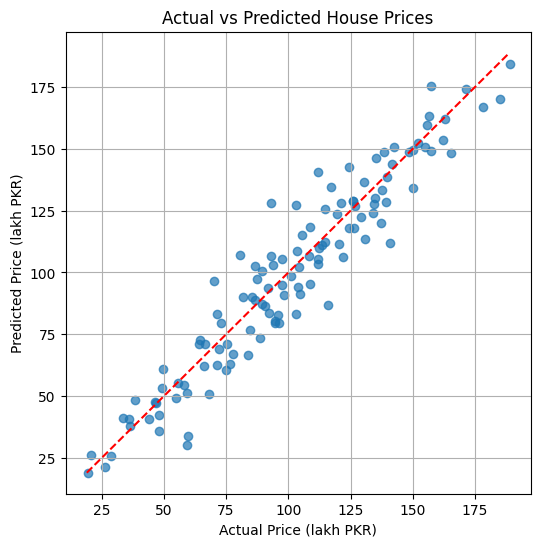

In [11]:
plt.figure(figsize=(6, 6))
plt.scatter(actual_prices, test_predictions, alpha=0.7)
minimum = min(actual_prices.min(), test_predictions.min())
maximum = max(actual_prices.max(), test_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], "r--")
plt.xlabel("Actual Price (lakh PKR)")
plt.ylabel("Predicted Price (lakh PKR)")
plt.title("Actual vs Predicted House Prices")
plt.grid(True)
plt.show()

## Bonus: Naye ghar ki price predict karein

Neeche apne ghar ki details change kar sakte hain:
- Area: square feet
- Bedrooms: number of bedrooms
- Age: years

Naye input par bhi **wahi training wala scaler** use karna zaroori hai.

In [12]:
new_house = np.array([[1800, 3, 8]], dtype=np.float32)  # 1800 sqft, 3 bedrooms, 8 years old

new_house_scaled = x_scaler.transform(new_house)
new_house_tensor = torch.tensor(new_house_scaled, dtype=torch.float32)

model.eval()
with torch.no_grad():
    predicted_scaled = model(new_house_tensor).numpy()

predicted_price = y_scaler.inverse_transform(predicted_scaled)[0, 0]
print(f"Estimated house price: {predicted_price:.2f} lakh PKR")

Estimated house price: 96.69 lakh PKR


## Students ke liye Practice

1. Hidden layer ke neurons `16` se `32` kar ke result compare karein.
2. Learning rate `0.01` se `0.001` karein. Loss graph mein kya farq aya?
3. Epochs `50`, `150` aur `300` karke MAE compare karein.
4. Ek aur hidden layer add karein.
5. New house ka area, bedrooms aur age change karke prediction karein.

## Important Concepts Recap

| Concept | Kaam |
|---|---|
| Features (X) | Area, bedrooms, age |
| Target (y) | House price |
| Train/Test Split | Learning aur fair testing |
| StandardScaler | Values ko scale karna |
| Tensor / DataLoader | PyTorch data handling |
| MLP | Neural network model |
| ReLU | Hidden layers ki activation |
| MSELoss | Prediction error |
| Adam | Weights update karna |
| Backpropagation | Gradients calculate karna |
| MAE / RMSE / R² | Model performance measure karna |

**Complete workflow:** Data → Split → Scale → Tensors → MLP → Loss + Optimizer → Training → Evaluation → New Prediction.